# AIML Minor Project: Diabetes Outcome Analysis and Prediction
Student: Samruddhi PJ  
Project type: Exploratory Data Analysis + Binary Classification  
Dataset: [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)

## 1. Problem statement
This project explores the Pima Indians Diabetes Database and builds a baseline model to classify the dataset's Outcome field (0 or 1) from the available numeric measurements. It also studies data quality, patterns, and model performance.

## 2. Objectives
- Understand the dataset's rows, columns, features, and target.
- Inspect missing values, duplicates, data types, and unusual zero values.
- Clean the data and document preprocessing decisions.
- Create at least four meaningful visualizations with observations.
- Train and evaluate a classification model using suitable metrics.
- Discuss limitations and possible improvements.

Important limitation: This is an educational dataset, not a medical diagnostic tool. Results must not be used to diagnose individuals. The dataset concerns a specific population and may not generalize to other groups.

## 3. Import libraries
The  pandas and NumPy for data handling, Matplotlib/Seaborn for visualization, and scikit-learn for preprocessing and modelling.

In [13]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, roc_auc_score
)

sns.set_theme()
pd.set_option("display.max_columns", None)

## 4. Load the dataset


In [14]:
DATA_SOURCE = "https://raw.githubusercontent.com/Kabin24/Pima-Indians-Diabetes-Dataset/main/diabetes.csv"  # public CSV mirror of the Kaggle dataset
# Alternative after downloading from Kaggle: DATA_SOURCE = "diabetes.csv"

try:
    df = pd.read_csv(DATA_SOURCE)
except Exception as e:
    print("Could not load the online CSV. Download diabetes.csv from Kaggle and set DATA_SOURCE='diabetes.csv'.")
    raise e

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 5. Understand the dataset
The commonly distributed dataset has eight input features and the target Outcome. Confirm the actual column names and row count from the loaded file rather than assuming them.

In [15]:
print("Column names:", df.columns.tolist())
display(df.info())
display(df.describe().T)

Column names: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


None

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


### Feature guide
- Pregnancies: number of pregnancies
- Glucose: glucose measurement
- BloodPressure: diastolic blood pressure
- SkinThickness: triceps skin-fold thickness
- Insulin: 2-hour serum insulin
- BMI: body mass index
- DiabetesPedigreeFunction: diabetes pedigree function
- Age: age in years
- Outcome: target label (0 or 1)

If the loaded file uses different column names, inspect df.columns and update the names below accordingly.

## 6. Check data quality
Check data types, missing values, duplicate rows, and zeros. In this dataset, zero measurements in Glucose, BloodPressure, SkinThickness, Insulin, and BMI can represent missing/invalid measurements rather than realistic values. We convert zeros in those columns to missing values, then impute them using the median within a modelling pipeline. We do not replace zero in Pregnancies or Outcome.

In [16]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values before cleaning:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())

zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
available_zero_cols = [c for c in zero_as_missing if c in df.columns]
for col in available_zero_cols:
    print(f"{col}: zero values =", int((df[col] == 0).sum()))

df_clean = df.copy()
for col in available_zero_cols:
    df_clean.loc[df_clean[col] == 0, col] = np.nan

# Remove exact duplicate rows if present; report how many were removed.
duplicates_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", duplicates_removed)
print("Missing values after zero handling:")
display(df_clean.isna().sum().to_frame("missing_count"))

Data types:


,dtype
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


Missing values before cleaning:


,missing_count
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Duplicate rows: 0
Glucose: zero values = 5
BloodPressure: zero values = 35
SkinThickness: zero values = 227
Insulin: zero values = 374
BMI: zero values = 11
Duplicate rows removed: 0
Missing values after zero handling:


,missing_count
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


## 7. Prepare features and target
The target is Outcome. The input features are all other columns. We split the data into training and testing sets before fitting the imputer/scaler/model, avoiding data leakage. Median imputation and scaling are performed inside a pipeline.

In [17]:
if "Outcome" not in df_clean.columns:
    raise ValueError("Expected target column 'Outcome'. Check the dataset column names.")

X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"].astype(int)

print("Target counts:")
display(y.value_counts().sort_index().rename(index={0: "Outcome 0", 1: "Outcome 1"}).to_frame("count"))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

Target counts:


,count
Outcome,
Outcome 0,500
Outcome 1,268


## 8. Visualization 1 — Target class distribution
**What to observe:** Compare the number of records with Outcome 0 and Outcome 1. If one class is much more common, accuracy alone may be misleading.

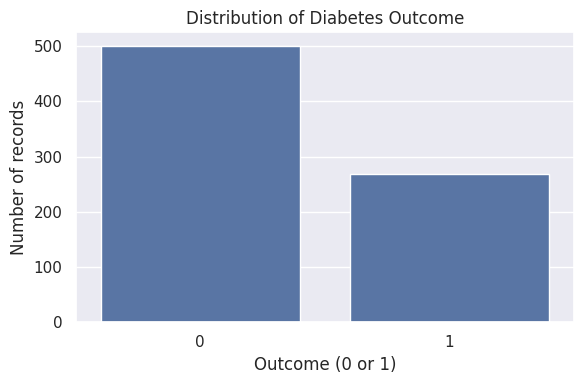

,proportion
Outcome,
0,0.651042
1,0.348958


In [18]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="Outcome")
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 or 1)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

display(df_clean["Outcome"].value_counts(normalize=True).rename("proportion").to_frame())

## 9. Visualization 2 — Glucose distribution by outcome
**What to observe:** Compare the distribution and median of glucose measurements across the two outcome groups. Describe what the plot shows; do not assume the relationship proves causation.

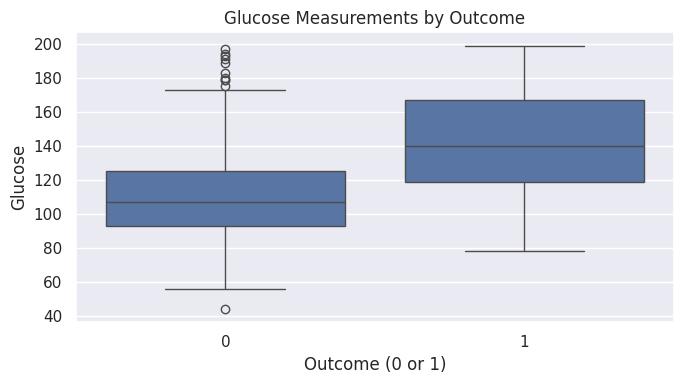

In [19]:
if "Glucose" in df_clean.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df_clean, x="Outcome", y="Glucose")
    plt.title("Glucose Measurements by Outcome")
    plt.xlabel("Outcome (0 or 1)")
    plt.ylabel("Glucose")
    plt.tight_layout()
    plt.show()
else:
    print("Glucose column not found; check column names.")

## 10. Visualization 3 — Feature correlation heatmap
**What to observe:** Correlation values range from -1 to +1. Positive values indicate variables tend to increase together; negative values indicate an inverse linear relationship. Correlation does not imply causation.

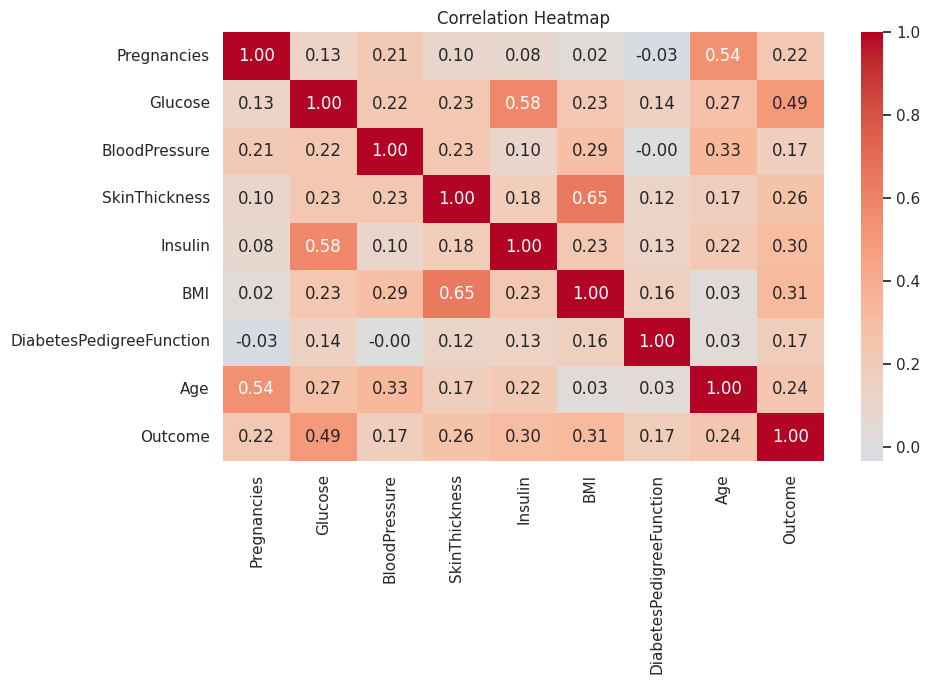

In [20]:
plt.figure(figsize=(10, 7))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 11. Visualization 4 — Age distribution by outcome
**What to observe:** Compare age distributions between the outcome groups and note any visible differences or overlap.

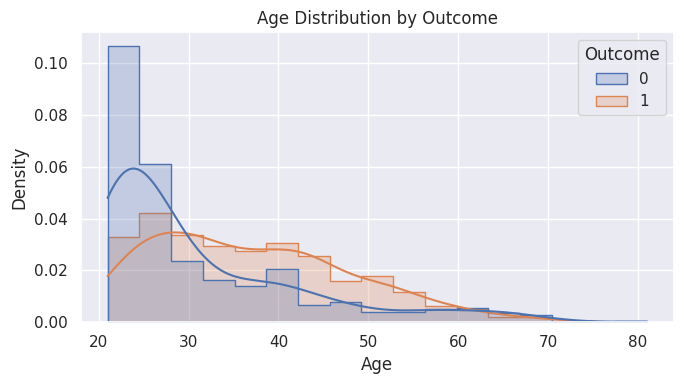

In [21]:
if "Age" in df_clean.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df_clean, x="Age", hue="Outcome", kde=True, element="step", stat="density", common_norm=False)
    plt.title("Age Distribution by Outcome")
    plt.tight_layout()
    plt.show()
else:
    print("Age column not found; check column names.")

## 12. Optional visualization 5 — BMI by outcome
This extra chart is useful if the dataset contains BMI. Describe the observed spread and overlap.

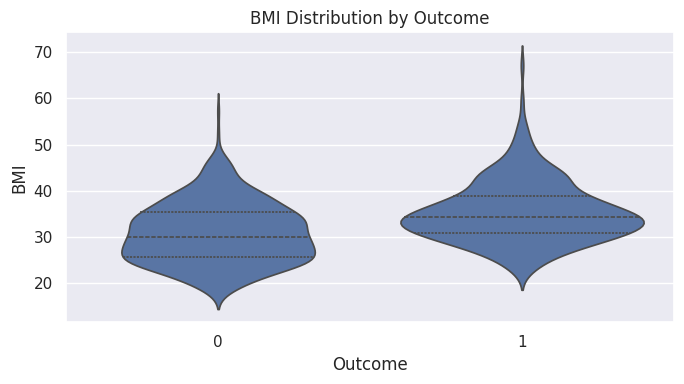

In [22]:
if "BMI" in df_clean.columns:
    plt.figure(figsize=(7, 4))
    sns.violinplot(data=df_clean, x="Outcome", y="BMI", inner="quartile")
    plt.title("BMI Distribution by Outcome")
    plt.tight_layout()
    plt.show()

## 13. Evaluate the model
We report accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix. The test set was held out from training. Scores describe this split and should not be treated as evidence of clinical readiness.

,Metric,Score
0,Accuracy,0.708
1,Precision,0.600
2,Recall,0.500
3,F1-score,0.545
4,ROC-AUC,0.813


              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



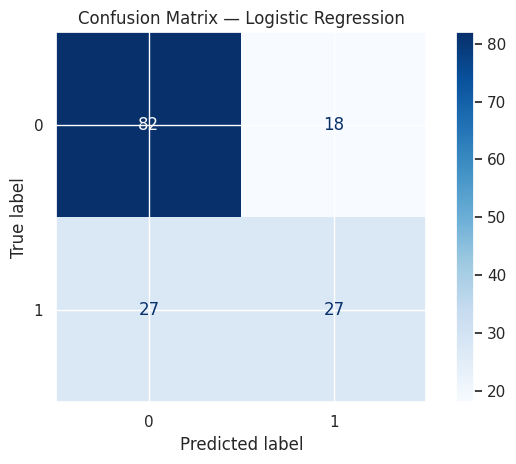

In [23]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
metrics_df = pd.DataFrame({"Metric": list(metrics.keys()), "Score": list(metrics.values())})
display(metrics_df.style.format({"Score": "{:.3f}"}))

print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()

## 14. Interpret the results
Use the actual values displayed above to write a short interpretation:
- Accuracy: overall proportion of correct predictions.
- Precision: among predicted positive cases, the proportion that were truly positive in the test labels.
- Recall: among actual positive cases, the proportion identified by the model.
- F1-score: balance between precision and recall.
- ROC-AUC: ability to rank positive cases above negative cases across thresholds.

Do not claim the model is suitable for diagnosis. Consider the class distribution, dataset limitations, and false negatives/false positives when interpreting results.

In [24]:
print("Project result summary (generated from this run):")
print(f"Rows after cleaning: {len(df_clean)}")
print(f"Features used: {X.shape[1]}")
print(f"Test records: {len(y_test)}")
print(f"Accuracy: {metrics['Accuracy']:.3f}")
print(f"Precision: {metrics['Precision']:.3f}")
print(f"Recall: {metrics['Recall']:.3f}")
print(f"F1-score: {metrics['F1-score']:.3f}")
print(f"ROC-AUC: {metrics['ROC-AUC']:.3f}")

Project result summary (generated from this run):
Rows after cleaning: 768
Features used: 8
Test records: 154
Accuracy: 0.708
Precision: 0.600
Recall: 0.500
F1-score: 0.545
ROC-AUC: 0.813


## 15. Conclusion, limitations, and future improvements

### Conclusion
This project demonstrates an end-to-end workflow: understanding a dataset, checking data quality, handling implausible zero measurements, exploring patterns with visualizations, training a Logistic Regression classifier, and evaluating it with multiple metrics. Write your final conclusion after running the notebook and reviewing the actual plots and scores.

### Limitations
- The dataset is relatively small and represents a specific population; results may not generalize.
- Some zero values are treated as missing based on feature meaning; this is an assumption and should be stated.
- Logistic Regression is a baseline model; different models and cross-validation could yield different results.
- This educational model is not a medical diagnostic tool.

### Future improvements
- Compare with Decision Tree and Random Forest using cross-validation.
- Tune model parameters and examine feature importance/coefficients carefully.
- Evaluate performance across relevant subgroups where appropriate.
- Use a larger, more representative dataset and consult domain experts for any real-world application.

## 16. References
1. Kaggle, *Pima Indians Diabetes Database*: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database
2. scikit-learn documentation: https://scikit-learn.org/stable/
3. pandas documentation: https://pandas.pydata.org/docs/
4. Seaborn documentation: https://seaborn.pydata.org/

